In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage

In [2]:
# Cargar una imagen de ejemplo
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
nombres_clases = ['avión', 'auto', 'pájaro', 'gato', 'venado',
                  'perro', 'rana', 'caballo', 'barco', 'camión']

# Normalizar y tomar una imagen
x_train = x_train.astype('float32') / 255.0
imagen_ejemplo = x_train[100]  # Tomar una imagen específica

print(f"Imagen seleccionada: {nombres_clases[y_train[100][0]]}")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1596s 9us/step
Imagen seleccionada: barco


In [3]:
# Crear modelo completo para extraer características
modelo = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, (3, 3), activation='relu', padding='same', name='conv1'),
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='conv2'),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv3'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(10, activation='softmax')
])

# Compilar modelo
modelo.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Entrenar brevemente para que los kernels tengan valores significativos
print("Entrenando modelo brevemente...")
modelo.fit(x_train[:1000], y_train[:1000], epochs=3, verbose=0)

Entrenando modelo brevemente...


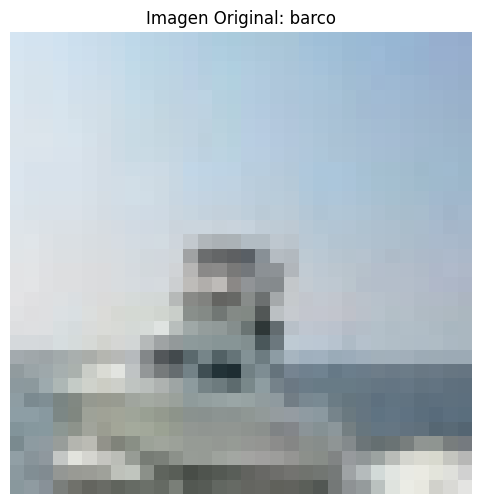

In [4]:
# Función para visualizar kernels
def visualizar_kernels(modelo, capa_nombre):
    # Obtener los pesos de la capa
    for layer in modelo.layers:
        if layer.name == capa_nombre:
            pesos = layer.get_weights()[0]  # Kernels
            break

    # Pesos tienen forma (altura, ancho, canales_entrada, num_filtros)
    print(f"Forma de kernels en {capa_nombre}: {pesos.shape}")

    num_filtros = pesos.shape[-1]
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    fig.suptitle(f'Kernels de la capa: {capa_nombre}')

    for i in range(min(8, num_filtros)):
        ax = axes[i//4, i%4]

        # Si es la primera capa (RGB), mostrar los 3 canales
        if pesos.shape[2] == 3:
            kernel = pesos[:, :, :, i]
            # Normalizar para visualización
            kernel = (kernel - kernel.min()) / (kernel.max() - kernel.min())
            ax.imshow(kernel)
        else:
            # Para capas posteriores, mostrar promedio de canales
            kernel = np.mean(pesos[:, :, :, i], axis=2)
            ax.imshow(kernel, cmap='viridis')

        ax.set_title(f'Filtro {i+1}')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Función para aplicar convolución manual y mostrar el proceso
def mostrar_convolucion_manual():
    # Convertir imagen a escala de grises para simplicidad
    img_gris = np.mean(imagen_ejemplo, axis=2)

    # Definir algunos kernels conocidos
    kernels = {
        'Detección de bordes verticales': np.array([[-1, 0, 1],
                                                   [-2, 0, 2],
                                                   [-1, 0, 1]]),
        'Detección de bordes horizontales': np.array([[-1, -2, -1],
                                                     [ 0,  0,  0],
                                                     [ 1,  2,  1]]),
        'Enfoque (Sharpening)': np.array([[ 0, -1,  0],
                                         [-1,  5, -1],
                                         [ 0, -1,  0]]),
        'Desenfoque (Blur)': np.array([[1, 1, 1],
                                      [1, 1, 1],
                                      [1, 1, 1]]) / 9
    }

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Mostrar imagen original
    axes[0, 0].imshow(img_gris, cmap='gray')
    axes[0, 0].set_title('Imagen Original')
    axes[0, 0].axis('off')

    # Mostrar cada kernel y su resultado
    for i, (nombre, kernel) in enumerate(kernels.items()):
        # Aplicar el kernel igual que lo hace una capa Conv2D (correlación cruzada,
        # sin voltear el kernel; ndimage.convolve sí lo voltearía)
        resultado = ndimage.correlate(img_gris, kernel)

        # Posición en la grilla
        fila = (i + 1) // 3
        col = (i + 1) % 3

        # Mostrar resultado
        axes[fila, col].imshow(resultado, cmap='gray')
        axes[fila, col].set_title(f'{nombre}')
        axes[fila, col].axis('off')

    # Ocultar el panel que queda vacío (hay 4 kernels + la imagen original = 5 de 6)
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

    # Mostrar los kernels utilizados
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    for i, (nombre, kernel) in enumerate(kernels.items()):
        axes[i].imshow(kernel, cmap='RdBu')
        axes[i].set_title(f'{nombre}\nKernel')
        axes[i].axis('off')

        # Añadir valores del kernel como texto
        for (j, k), val in np.ndenumerate(kernel):
            axes[i].text(k, j, f'{val:.1f}', ha='center', va='center',
                        color='white' if abs(val) > 0.5 else 'black')

    plt.tight_layout()
    plt.show()

# Función para visualizar mapas de características
def visualizar_mapas_caracteristicas(imagen):
    imagen_batch = np.expand_dims(imagen, axis=0)

    # Modelo "extractor": usa las MISMAS capas (y pesos entrenados) del modelo original,
    # pero devuelve la salida de cada capa convolucional en lugar de la predicción final
    nombres_capas = ['conv1', 'conv2', 'conv3']
    extractor = keras.Model(inputs=modelo.inputs,
                            outputs=[modelo.get_layer(n).output for n in nombres_capas])

    # Una sola pasada: devuelve una lista con los mapas de conv1, conv2 y conv3
    salidas = extractor.predict(imagen_batch, verbose=0)

    for nombre, mapas in zip(nombres_capas, salidas):
        mapas = mapas[0]  # Quitar la dimensión del batch -> (alto, ancho, num_filtros)

        # Visualizar los primeros 8 mapas
        fig, axes = plt.subplots(2, 4, figsize=(12, 6))
        fig.suptitle(f'Mapas de características - {nombre}')

        for j in range(8):
            ax = axes[j//4, j%4]
            ax.imshow(mapas[:, :, j], cmap='viridis')
            ax.set_title(f'Mapa {j+1}')
            ax.axis('off')

        plt.tight_layout()
        plt.show()

# Mostrar imagen original
plt.figure(figsize=(6, 6))
plt.imshow(imagen_ejemplo)
plt.title(f'Imagen Original: {nombres_clases[y_train[100][0]]}')
plt.axis('off')
plt.show()

=== 1. KERNELS APRENDIDOS POR EL MODELO ===
Forma de kernels en conv1: (3, 3, 3, 8)


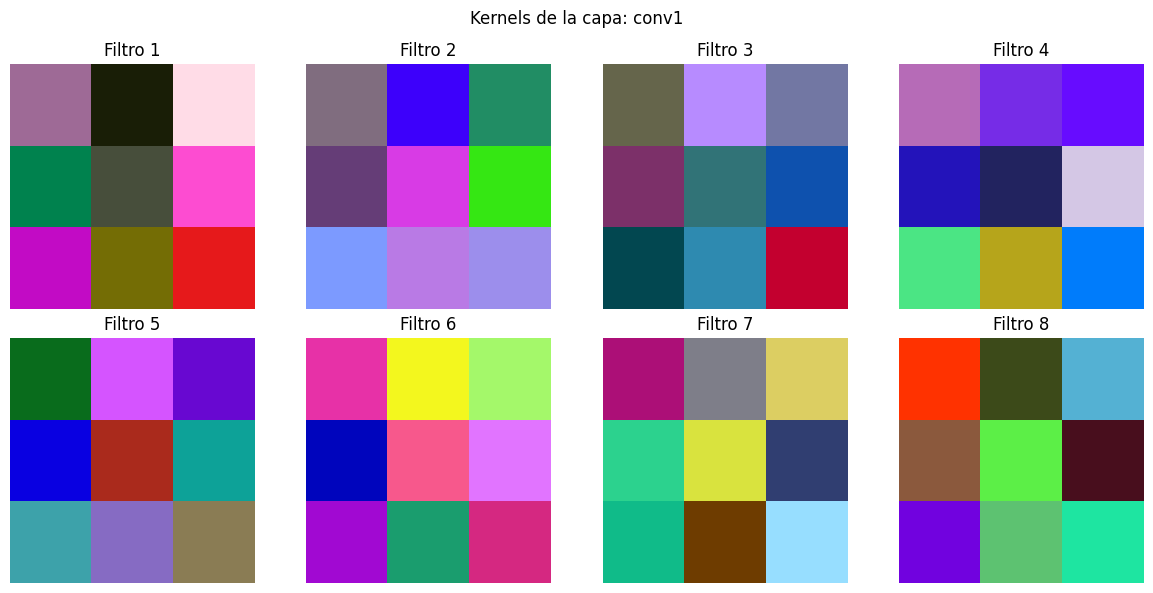

In [5]:
print("=== 1. KERNELS APRENDIDOS POR EL MODELO ===")
visualizar_kernels(modelo, 'conv1')


=== 2. CONVOLUCIONES MANUALES CON KERNELS CONOCIDOS ===


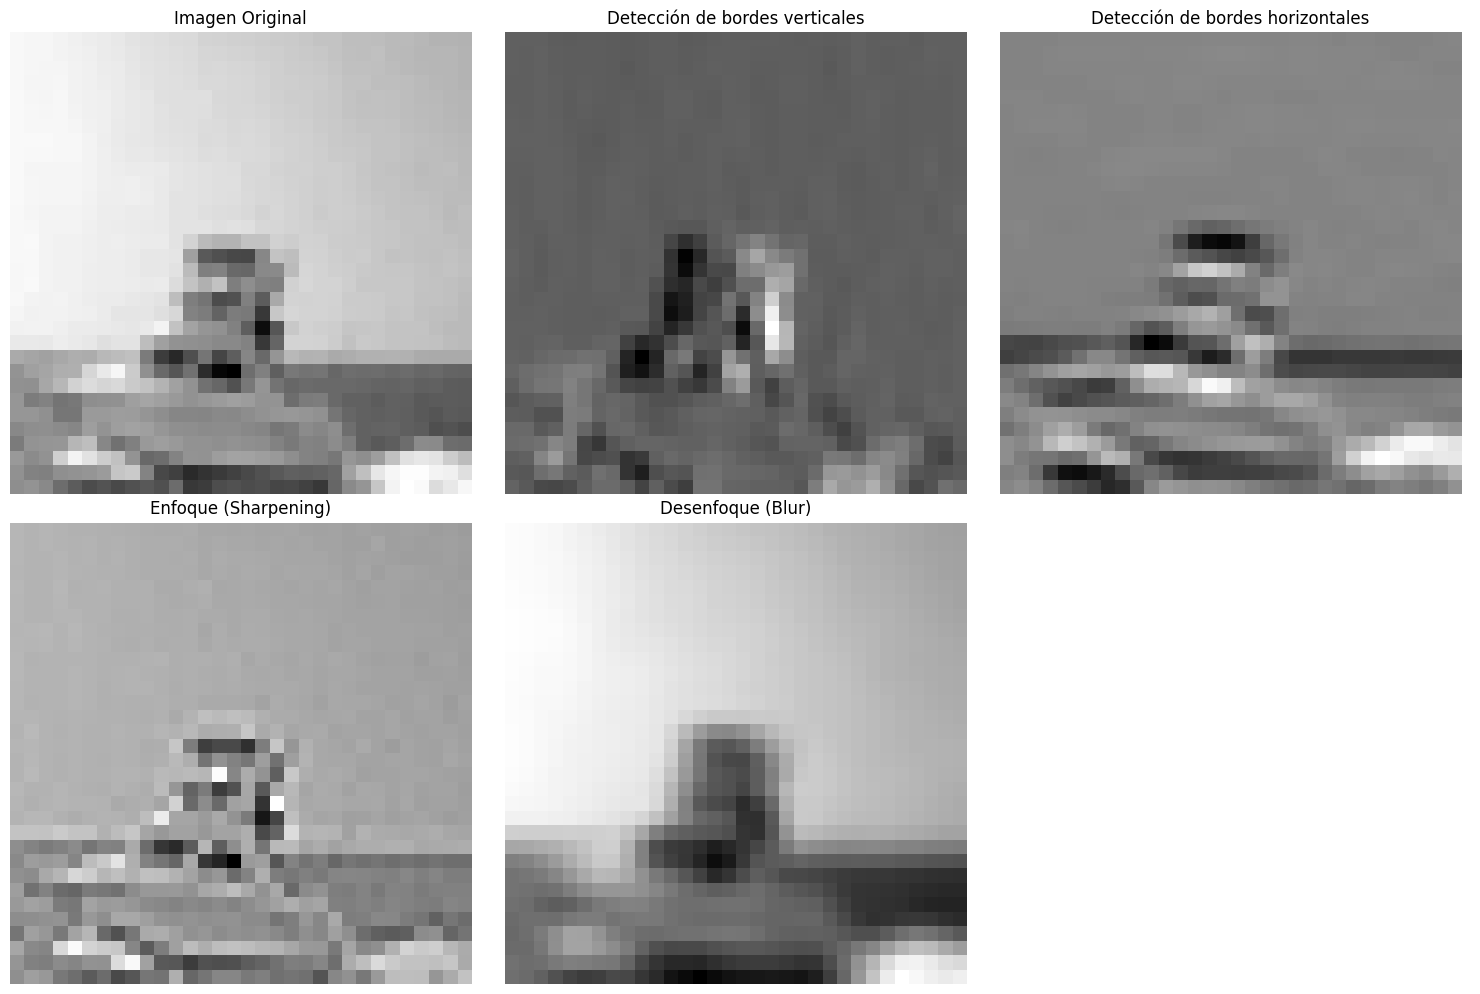

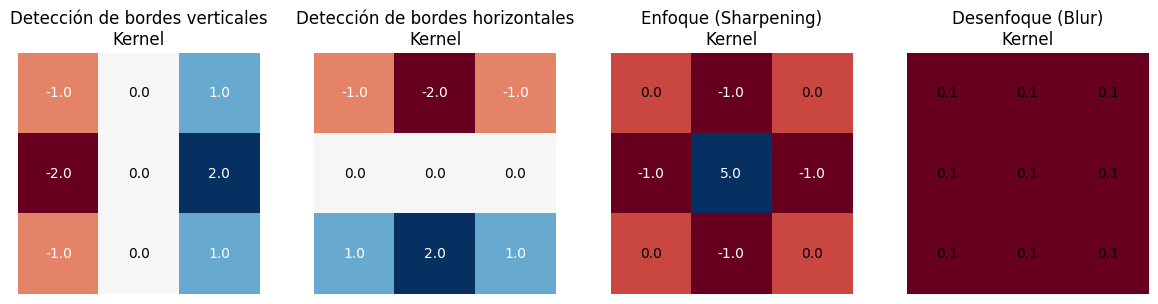

In [6]:
print("\n=== 2. CONVOLUCIONES MANUALES CON KERNELS CONOCIDOS ===")
mostrar_convolucion_manual()


=== 3. MAPAS DE CARACTERÍSTICAS POR CAPA ===


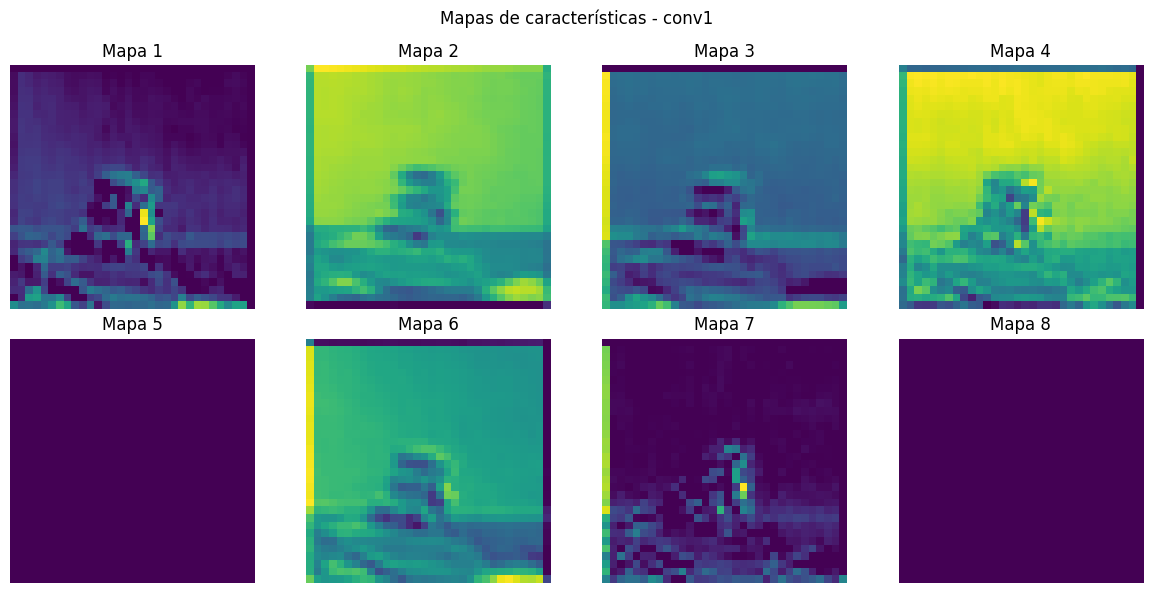

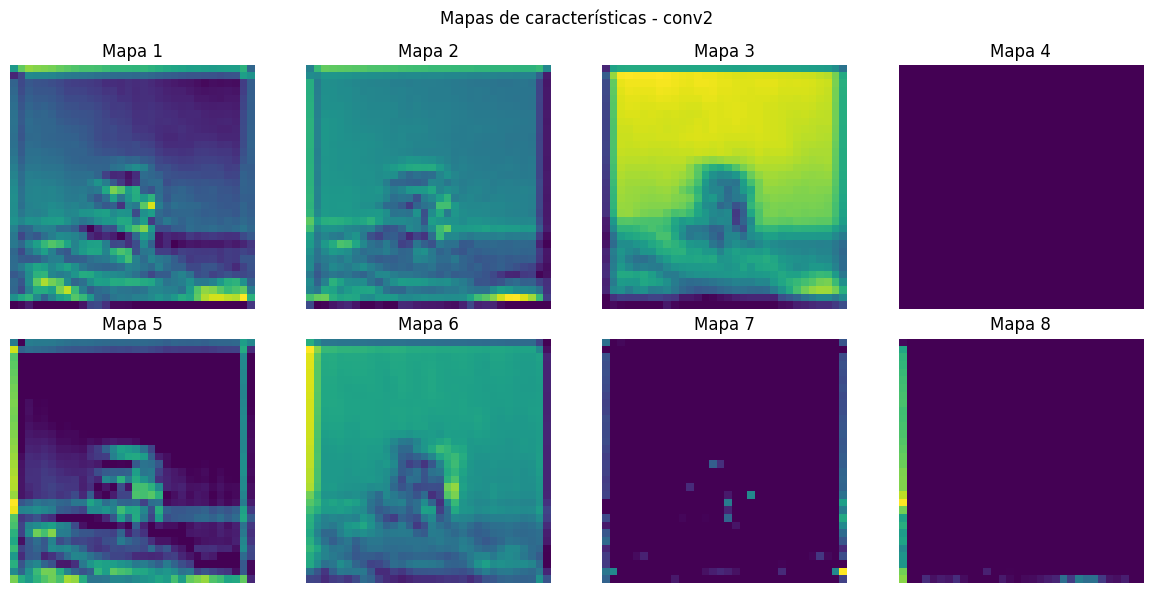

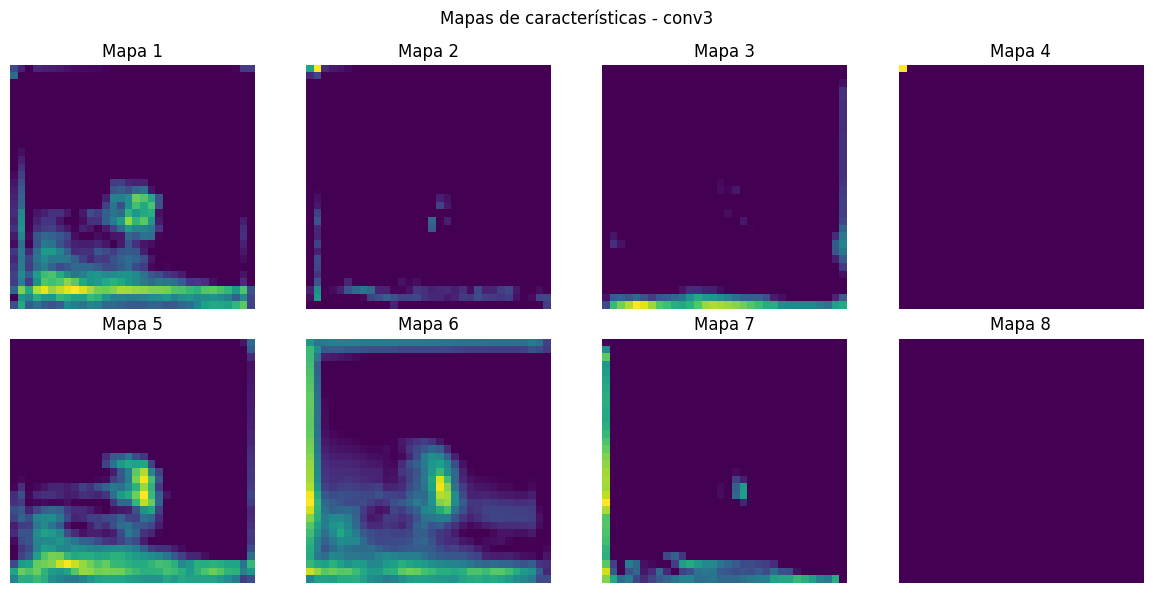


=== EXPLICACIÓN ===
• Los KERNELS son filtros pequeños (3x3) que detectan patrones específicos
• Cada kernel se desliza por toda la imagen multiplicando y sumando valores
• Los kernels aprendidos automáticamente detectan bordes, texturas, formas
• Los mapas de características muestran dónde cada kernel encontró patrones
• Las capas más profundas detectan patrones más complejos


In [7]:
print("\n=== 3. MAPAS DE CARACTERÍSTICAS POR CAPA ===")
visualizar_mapas_caracteristicas(imagen_ejemplo)

print("\n=== EXPLICACIÓN ===")
print("• Los KERNELS son filtros pequeños (3x3) que detectan patrones específicos")
print("• Cada kernel se desliza por toda la imagen multiplicando y sumando valores")
print("• Los kernels aprendidos automáticamente detectan bordes, texturas, formas")
print("• Los mapas de características muestran dónde cada kernel encontró patrones")
print("• Las capas más profundas detectan patrones más complejos")